In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, time, os
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve, matthews_corrcoef)
SEED = 42
DATA_PATH = 'creditcard.csv'
os.makedirs('outputs', exist_ok=True)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


In [ ]:
# Memuat data: coba (1) file lokal, (2) unduh otomatis via kagglehub, (3) unggah manual (Colab)
import glob
if not os.path.exists(DATA_PATH):
    try:
        import kagglehub
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
        import kagglehub
    try:
        folder = kagglehub.dataset_download('mlg-ulb/creditcardfraud')
        DATA_PATH = glob.glob(os.path.join(folder, '**', 'creditcard.csv'), recursive=True)[0]
        print('Data diunduh ke:', DATA_PATH)
    except Exception as e:
        print('Unduh otomatis gagal:', e)
        try:
            from google.colab import files
            print('Silakan unggah creditcard.csv (dari Kaggle) pada dialog berikut.')
            files.upload()
            DATA_PATH = 'creditcard.csv'
        except ImportError:
            raise FileNotFoundError('Letakkan creditcard.csv di folder notebook atau ubah DATA_PATH.')
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
print('Missing values total:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
df.info()
df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Data diunduh ke: /kaggle/input/creditcardfraud/creditcard.csv
Shape: (284807, 31)
Missing values total: 0
Duplicate rows: 1081
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


Class
0    284315
1       492
Name: count, dtype: int64
Persentase fraud: 0.1727%
Rasio imbalance (normal:fraud) = 577.9 : 1


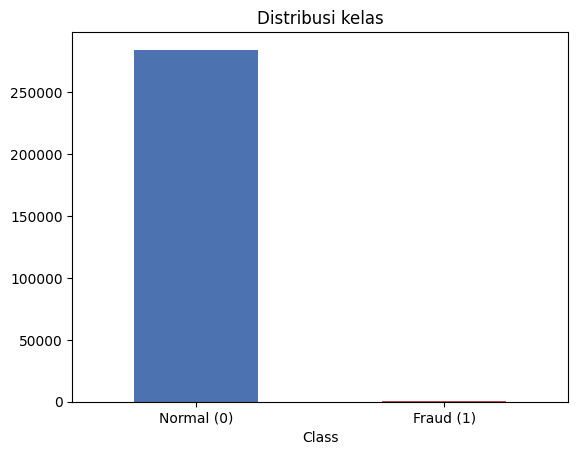

In [ ]:
vc = df['Class'].value_counts()
print(vc)
print('Persentase fraud: %.4f%%' % (100*vc[1]/len(df)))
print('Rasio imbalance (normal:fraud) = %.1f : 1' % (vc[0]/vc[1]))
ax = vc.plot(kind='bar', color=['#4c72b0','#c44e52']); ax.set_title('Distribusi kelas'); ax.set_xticklabels(['Normal (0)','Fraud (1)'], rotation=0)
plt.savefig('outputs/fig_class_distribution.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
df[['Time','Amount']].describe()

,Time,Amount
count,"284,807.0000","284,807.0000"
mean,"94,813.8596",88.3496
std,"47,488.1460",250.1201
min,0.0000,0.0000
25%,"54,201.5000",5.6000
50%,"84,692.0000",22.0000
75%,"139,320.5000",77.1650
max,"172,792.0000","25,691.1600"


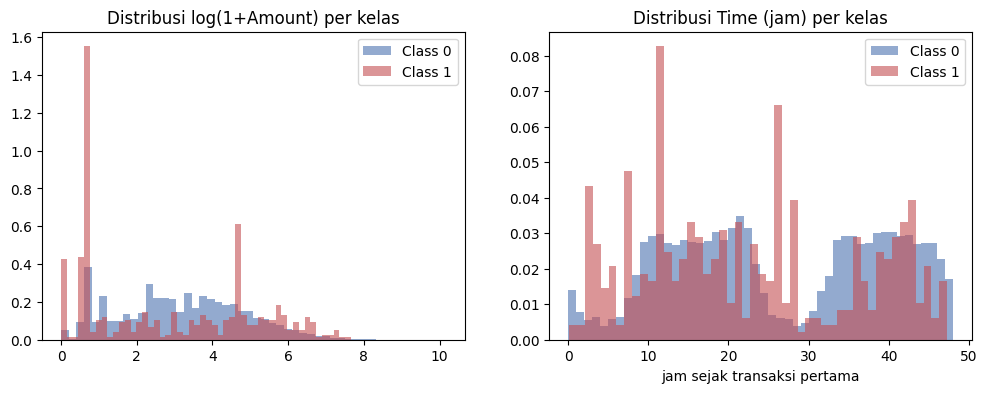

             count     mean      std    min    25%     50%      75%  \
Class                                                                 
0     284,315.0000  88.2910 250.1051 0.0000 5.6500 22.0000  77.0500   
1         492.0000 122.2113 256.6833 0.0000 1.0000  9.2500 105.8900   

              max  
Class              
0     25,691.1600  
1      2,125.8700  


In [ ]:
# EDA

fig, ax = plt.subplots(1,2, figsize=(12,4))
for c,col in zip([0,1],['#4c72b0','#c44e52']):
    ax[0].hist(np.log1p(df.loc[df.Class==c,'Amount']), bins=50, alpha=.6, label=f'Class {c}', color=col, density=True)
ax[0].set_title('Distribusi log(1+Amount) per kelas'); ax[0].legend()
for c,col in zip([0,1],['#4c72b0','#c44e52']):
    ax[1].hist(df.loc[df.Class==c,'Time']/3600, bins=48, alpha=.6, label=f'Class {c}', color=col, density=True)
ax[1].set_title('Distribusi Time (jam) per kelas'); ax[1].set_xlabel('jam sejak transaksi pertama'); ax[1].legend()
plt.savefig('outputs/fig_amount_time.png', dpi=150, bbox_inches='tight'); plt.show()
print(df.groupby('Class')['Amount'].describe())

V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
V3    -0.1930
V7    -0.1873
V11    0.1549
V4     0.1334
V18   -0.1115
Name: Class, dtype: float64


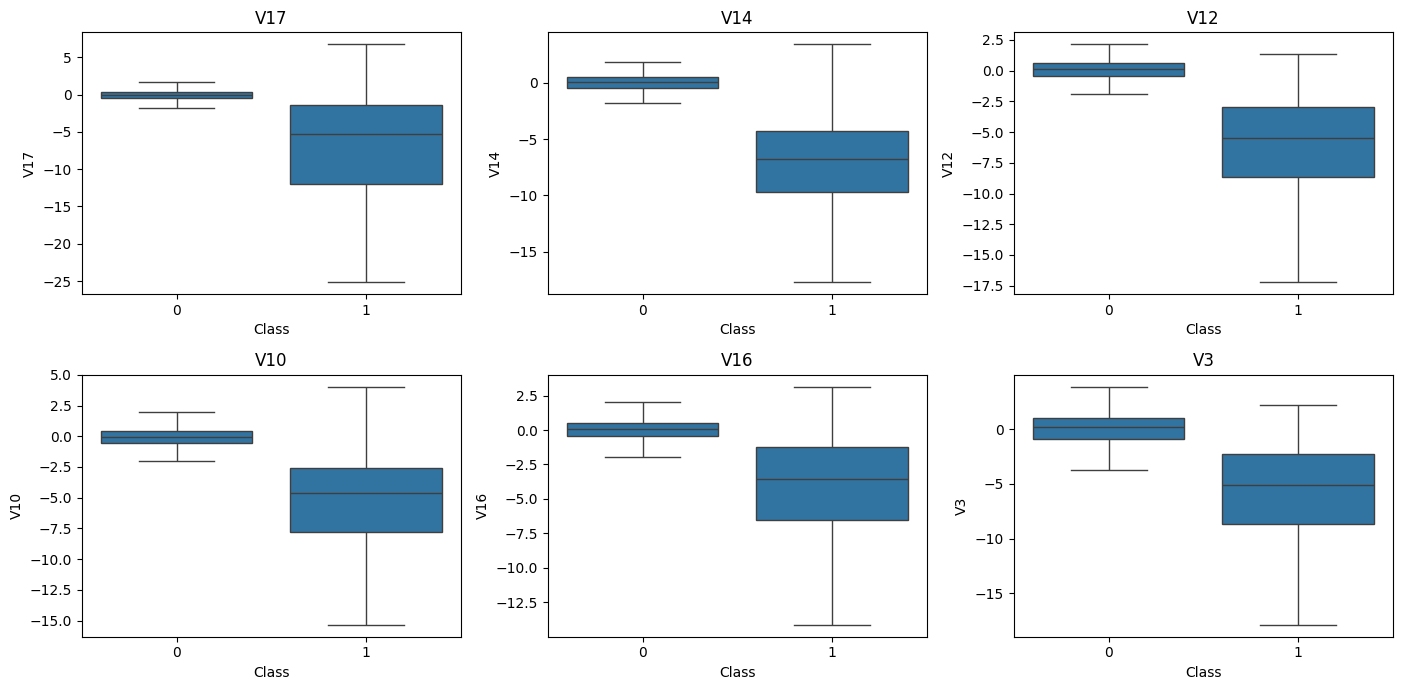

In [ ]:
corr = df.corr()['Class'].drop('Class').sort_values(key=abs, ascending=False)
print(corr.head(10))
top = corr.head(6).index.tolist()
fig, axes = plt.subplots(2,3, figsize=(14,7))
for a,f in zip(axes.ravel(), top):
    sns.boxplot(data=df, x='Class', y=f, ax=a, showfliers=False); a.set_title(f)
plt.tight_layout(); plt.savefig('outputs/fig_top_features.png', dpi=150); plt.show()

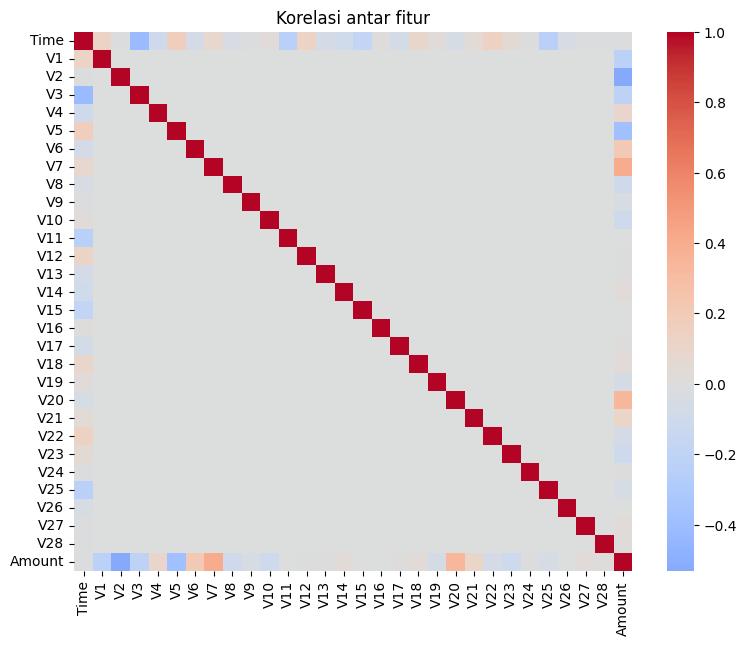

In [ ]:
# Korelasi antar fitur (V1-V28 hasil PCA seharusnya hampir tidak berkorelasi)
plt.figure(figsize=(9,7)); sns.heatmap(df.drop(columns='Class').corr(), cmap='coolwarm', center=0)
plt.title('Korelasi antar fitur'); plt.savefig('outputs/fig_corr.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
# Preprocessing dan feature engineering

def add_features(d):
    d = d.copy()
    d['Amount_log'] = np.log1p(d['Amount'])
    d['Hour'] = (d['Time'] // 3600) % 24
    return d

X = df.drop(columns='Class'); y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Train:', X_train.shape, 'fraud =', int(y_train.sum()))
print('Test :', X_test.shape,  'fraud =', int(y_test.sum()))

X_train_fe, X_test_fe = add_features(X_train), add_features(X_test)
base_cols = [c for c in X_train.columns]
fe_cols   = base_cols + ['Amount_log','Hour']
scale_cols_base = ['Time','Amount']
scale_cols_fe   = ['Time','Amount','Amount_log','Hour']


Train: (227845, 30) fraud = 394
Test : (56962, 30) fraud = 98


In [ ]:
# Desain Evaluasi

def make_pipe(model, cols, scale_cols):
    pre = ColumnTransformer([('sc', RobustScaler(), scale_cols)], remainder='passthrough')
    return Pipeline([('pre', pre), ('clf', model)])

candidates = {
 'Baseline Dummy (prior)':        (DummyClassifier(strategy='prior'), 'base'),
 'Logistic Regression':           (LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED), 'base'),
 'Logistic Regression + FE':      (LogisticRegression(max_iter=2000, class_weight='balanced', random_state=SEED), 'fe'),
 'Decision Tree':                 (DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=SEED), 'base'),
 'Random Forest':                 (RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED), 'base'),
 'Random Forest + FE':            (RandomForestClassifier(n_estimators=200, class_weight='balanced_subsample', n_jobs=-1, random_state=SEED), 'fe'),
}
def get(fe):
    return (X_train_fe[fe_cols], fe_cols, scale_cols_fe) if fe=='fe' else (X_train[base_cols], base_cols, scale_cols_base)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'pr_auc':'average_precision','recall':'recall','precision':'precision','f1':'f1','roc_auc':'roc_auc'}
cv_rows=[]
for name,(m,fe) in candidates.items():
    Xtr, cols, sc = get(fe)
    t=time.time()
    res = cross_validate(make_pipe(m, cols, sc), Xtr, y_train, cv=skf, scoring=scoring, n_jobs=1)
    row={'Model':name}
    for k in scoring: row[k+'_mean']=res['test_'+k].mean(); row[k+'_std']=res['test_'+k].std()
    row['time_s']=time.time()-t
    cv_rows.append(row); print(name,'selesai', round(row['time_s'],1),'s')
cv_df = pd.DataFrame(cv_rows); cv_df.to_csv('outputs/cv_results.csv', index=False)
cv_df

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.p

Baseline Dummy (prior) selesai 1.7 s
Logistic Regression selesai 17.0 s
Logistic Regression + FE selesai 18.2 s
Decision Tree selesai 65.2 s
Random Forest selesai 1353.8 s
Random Forest + FE selesai 1242.5 s


,Model,pr_auc_mean,pr_auc_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,time_s
0,Baseline Dummy (prior),0.0017,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,1.7394
1,Logistic Regression,0.7567,0.0514,0.9138,0.0230,0.0630,0.0037,0.1178,0.0063,0.9826,0.0100,17.0465
2,Logistic Regression + FE,0.7575,0.0518,0.9112,0.0329,0.0590,0.0029,0.1108,0.0048,0.9842,0.0097,18.2475
3,Decision Tree,0.5078,0.0650,0.8401,0.0315,0.0598,0.0093,0.1115,0.0163,0.8851,0.0303,65.2383
4,Random Forest,0.8421,0.0189,0.7437,0.0385,0.9469,0.0288,0.8319,0.0189,0.9572,0.0151,"1,353.8381"
5,Random Forest + FE,0.8439,0.0284,0.7360,0.0371,0.9464,0.0270,0.8269,0.0165,0.9571,0.0169,"1,242.5454"


In [ ]:
# Evaluasi pada data uji

test_rows=[]; fitted={}
for name,(m,fe) in candidates.items():
    Xtr, cols, sc = get(fe)
    Xte = (X_test_fe[fe_cols] if fe=='fe' else X_test[base_cols])
    pipe = make_pipe(m, cols, sc).fit(Xtr, y_train)
    fitted[name]=(pipe,Xte)
    proba = pipe.predict_proba(Xte)[:,1]; pred = (proba>=0.5).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_test, pred).ravel()
    test_rows.append({'Model':name,'PR-AUC':average_precision_score(y_test,proba),'ROC-AUC':roc_auc_score(y_test,proba),
        'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred),
        'F1':f1_score(y_test,pred),'MCC':matthews_corrcoef(y_test,pred),'TP':tp,'FP':fp,'FN':fn,'TN':tn})
test_df = pd.DataFrame(test_rows); test_df.to_csv('outputs/test_results.csv', index=False)
test_df

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1,MCC,TP,FP,FN,TN
0,Baseline Dummy (prior),0.0017,0.5000,0.0000,0.0000,0.0000,0.0000,0,0,98,56864
1,Logistic Regression,0.7175,0.9720,0.0609,0.9184,0.1142,0.2330,90,1388,8,55476
2,Logistic Regression + FE,0.7226,0.9733,0.0565,0.9082,0.1064,0.2229,89,1486,9,55378
3,Decision Tree,0.4643,0.9121,0.0597,0.8673,0.1118,0.2241,85,1338,13,55526
4,Random Forest,0.8622,0.9676,0.9615,0.7653,0.8523,0.8576,75,3,23,56861
5,Random Forest + FE,0.8745,0.9573,0.9605,0.7449,0.8391,0.8456,73,3,25,56861


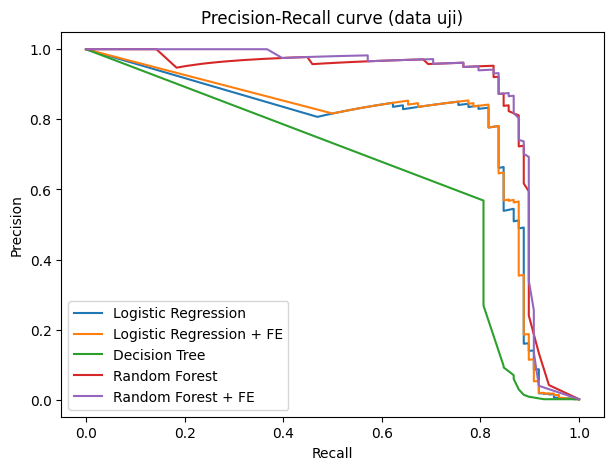

In [ ]:
plt.figure(figsize=(7,5))
for name,(pipe,Xte) in fitted.items():
    if 'Dummy' in name: continue
    p,r,_ = precision_recall_curve(y_test, pipe.predict_proba(Xte)[:,1]); plt.plot(r,p,label=name)
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title('Precision-Recall curve (data uji)'); plt.legend()
plt.savefig('outputs/fig_pr_curve.png', dpi=150, bbox_inches='tight'); plt.show()

V14   0.1718
V10   0.1295
V4    0.1044
V12   0.0972
V11   0.0819
V17   0.0721
V3    0.0476
V16   0.0412
V7    0.0316
V2    0.0275
dtype: float64


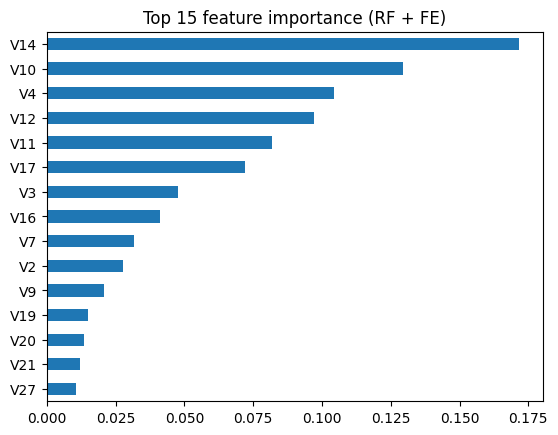

In [ ]:
# Feature importance Random Forest + FE
rf = fitted['Random Forest + FE'][0]
names = rf.named_steps['pre'].get_feature_names_out()
imp = pd.Series(rf.named_steps['clf'].feature_importances_, index=[n.split('__')[-1] for n in names]).sort_values(ascending=False)
print(imp.head(10)); imp.head(15)[::-1].plot(kind='barh', title='Top 15 feature importance (RF + FE)')
plt.savefig('outputs/fig_importance.png', dpi=150, bbox_inches='tight'); plt.show()

In [ ]:
   !zip -r outputs.zip outputs
   from google.colab import files
   files.download('outputs.zip')

  adding: outputs/ (stored 0%)
  adding: outputs/fig_top_features.png (deflated 28%)
  adding: outputs/fig_pr_curve.png (deflated 8%)
  adding: outputs/fig_class_distribution.png (deflated 29%)
  adding: outputs/fig_amount_time.png (deflated 21%)
  adding: outputs/cv_results.csv (deflated 47%)
  adding: outputs/test_results.csv (deflated 45%)
  adding: outputs/fig_corr.png (deflated 24%)
  adding: outputs/fig_importance.png (deflated 24%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sys, sklearn
import pandas as pd
import numpy as np
print('Python      :', sys.version.split()[0])
print('scikit-learn:', sklearn.__version__)
print('pandas      :', pd.__version__)
print('numpy       :', np.__version__)

Python      : 3.13.18
scikit-learn: 1.6.1
pandas      : 2.2.3
numpy       : 2.4.6
